# Main findings

Reproduces the main results from the files in `data/`. Run the cells top to bottom.

1. Local pages: how often a town's own election story reaches its Google News Local page, by town size
2. Front page: how often each outlet group gets the lead slot of a story, compared with an equal chance
3. Front page: lead rate when an outlet published first
4. Front page: smaller outlets' lead ratio over time, around the Online News Act milestones
5. Search: the same lead ratio in Google News search and Google Search
6. Civic outcomes: acclaimed mayors in small towns with and without their own news outlet

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = 'data'
SMALL = {'local_en', 'franco', 'diaspora'}   # paid outlets whose parent business got under $2M in CJC Year 2
ORANGE, BLUE, GREY = '#e66100', '#3b6fb6', '#8c8c8c'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
rng = np.random.default_rng(6450)

OUT = Path('outputs/milestone1'); OUT.mkdir(exist_ok=True)   # charts are saved here
def save(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 1. Local pages: is a town's own election story shown?

One reading of each town's Google News Local page (Oct 10–11, 2026). Counted only for towns where a story about the town's own race exists: `served` = shown on the page; `gap_recent` / `gap_older` = it exists but is not shown.

               shown  towns     share
band                                 
<2,000             7     30  0.233333
2,000-9,999       42     81  0.518519
10,000-49,999     72     92  0.782609
50,000+           39     42  0.928571


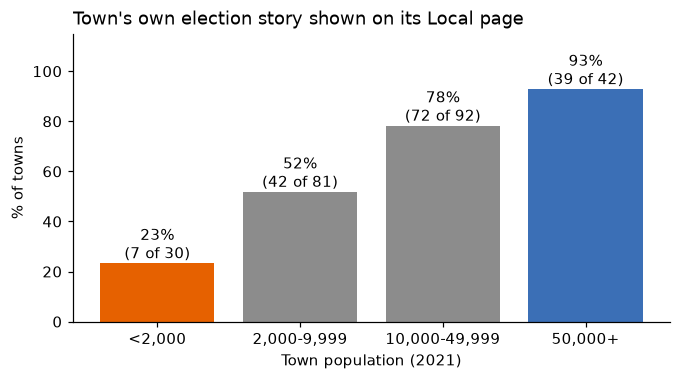

In [2]:
towns = pd.read_csv(f'{DATA}/google_news_local_pages/local_page_by_town.csv')
band = towns.pop_band.replace({'50,000-199,999': '50,000+', '200,000+': '50,000+'})
order = ['<2,000', '2,000-9,999', '10,000-49,999', '50,000+']
has_story = towns.outcome.isin(['served', 'gap_recent', 'gap_older'])
t = (towns[has_story].assign(band=band, shown=towns.outcome.eq('served'))
     .groupby('band').shown.agg(shown='sum', towns='count').reindex(order))
t['share'] = t.shown / t.towns
print(t)

fig, ax = plt.subplots(figsize=(7, 3.4))
bars = ax.bar(t.index, t.share * 100, color=[ORANGE, GREY, GREY, BLUE])
for b, (_, r) in zip(bars, t.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f"{r.share:.0%}\n({int(r.shown)} of {int(r.towns)})", ha='center')
ax.set_ylim(0, 115); ax.set_ylabel('% of towns'); ax.set_xlabel('Town population (2021)')
ax.set_title("Town's own election story shown on its Local page", loc='left')
save(fig, '1_local_pages_by_town_size')

## 2. Front page: who gets the lead slot?

Internet Archive snapshots of Google News Canada, 2022–2026 (`purpose = main`, minus the 5 excluded snapshots), Top stories section only.

A story card holds 2+ articles from different outlets; the first one is the **lead**. If every article in a card had the same chance, an article in a card of 4 would lead 1 time in 4.

**lead ratio = leads received ÷ leads expected under equal chance** (1 = in proportion to presence). YouTube videos are not counted as competitors for the lead. Intervals: 95% bootstrap over snapshots.

1,336 snapshots, 12,382 Top-stories slots, 2,175 story clusters
edition                group  leads  expected  lead_ratio  ci_low  ci_high
  en-CA Smaller paid outlets      8      33.7        0.24    0.09     0.40
  en-CA   Canadian, not paid     11      23.0        0.48    0.23     0.75
  en-CA    Major paid groups    824     780.9        1.06    1.02     1.09
  en-CA              Foreign    442     437.9        1.01    0.96     1.06
  fr-CA Smaller paid outlets     44     120.8        0.36    0.27     0.46
  fr-CA   Canadian, not paid      8      25.5        0.31    0.12     0.54
  fr-CA    Major paid groups    825     693.1        1.19    1.17     1.22
  fr-CA              Foreign      8      39.1        0.20    0.08     0.35
   both Smaller paid outlets     52     154.5        0.34    0.25     0.42
   both   Canadian, not paid     19      48.5        0.39    0.24     0.56
   both    Major paid groups   1649    1474.0        1.12    1.10     1.14
   both              Foreign    450 

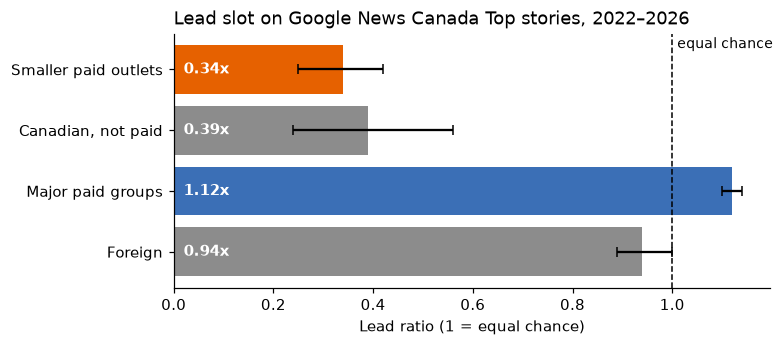

In [3]:
art = pd.read_csv(f'{DATA}/google_news_front_page/front_page_articles.csv', dtype={'timestamp': str})
snaps = pd.read_csv(f'{DATA}/google_news_front_page/snapshots.csv', dtype={'timestamp': str})
use = snaps[(snaps.purpose == 'main') & snaps.downloaded.astype(str).eq('True') & ~snaps.exclude.astype(str).eq('True')]

s = art[art.timestamp.isin(use.timestamp) & art.section.isin(['Top stories', 'À la une'])].copy()
s['group'] = s.group.fillna('unknown')
s['small'] = s.group.isin(SMALL)
s['lead'] = s.slot == 0
s['video'] = s.outlet.astype(str).str.startswith('youtube.com')
key = ['timestamp', 'card']
n_nonvideo = s[~s.video].groupby(key).size().rename('n_nonvideo')
video_led = s[s.video & s.lead].groupby(key).size().rename('video_led')
s = s.join(n_nonvideo, on=key).join(video_led, on=key)
s['cluster_size'] = s.n_nonvideo.fillna(0).astype(int)
s['in_cluster'] = ~s.video & (s.cluster_size >= 2) & s.video_led.isna()
cl = s[s.in_cluster].copy()
cl['expected'] = 1 / cl.cluster_size
print(f"{s.timestamp.nunique():,} snapshots, {len(s):,} Top-stories slots, {int(cl.lead.sum()):,} story clusters")

def lead_ratio(d, mask, n_boot=2000):
    per = d.assign(l=d.lead & mask, e=d.expected.where(mask, 0)).groupby('timestamp')[['l', 'e']].sum().to_numpy(float)
    idx = rng.integers(0, len(per), (n_boot, len(per)))
    boot = per[idx, 0].sum(1) / per[idx, 1].sum(1)
    return per[:, 0].sum() / per[:, 1].sum(), *np.percentile(boot, [2.5, 97.5]), int(per[:, 0].sum()), per[:, 1].sum()

groups = {'Smaller paid outlets': cl.small, 'Canadian, not paid': cl.group.eq('cdn_unpaid'),
          'Major paid groups': cl.group.eq('major'), 'Foreign': cl.group.eq('foreign')}
rows = []
for ed in ['en-CA', 'fr-CA', 'both']:
    d = cl if ed == 'both' else cl[cl.edition == ed]
    for name, m in groups.items():
        r, lo, hi, leads, exp = lead_ratio(d, m.loc[d.index])
        rows.append({'edition': ed, 'group': name, 'leads': leads, 'expected': round(exp, 1),
                     'lead_ratio': round(r, 2), 'ci_low': round(lo, 2), 'ci_high': round(hi, 2)})
lr = pd.DataFrame(rows)
print(lr.to_string(index=False))

b = lr[lr.edition == 'both'].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3))
colors = [{'Smaller paid outlets': ORANGE, 'Major paid groups': BLUE}.get(g, GREY) for g in b.group]
ax.barh(b.group, b.lead_ratio, xerr=[b.lead_ratio - b.ci_low, b.ci_high - b.lead_ratio], color=colors, capsize=3)
ax.axvline(1, ls='--', color='black', lw=1); ax.text(1.01, 3.35, 'equal chance', fontsize=9)
for i, v in enumerate(b.lead_ratio):
    ax.text(0.02, i, f'{v:.2f}x', va='center', color='white', fontweight='bold')
ax.set_xlabel('Lead ratio (1 = equal chance)')
ax.set_title('Lead slot on Google News Canada Top stories, 2022–2026', loc='left')
save(fig, '2_lead_ratio_by_group')

## 3. Front page: when an outlet published first, did it lead?

Within each story card, the article with the earliest publication time is "first". Google has said since 2019 that it elevates original reporting.

                      first in card  led when first  lead rate when first
Smaller paid outlets            179               8              0.044693
Major paid groups              1490             234              0.157047


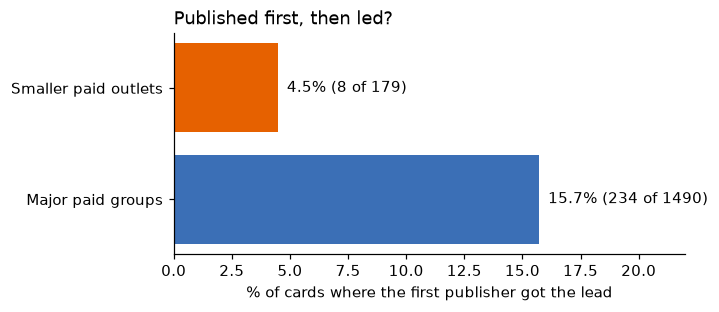

In [4]:
cl['cid'] = cl.timestamp + '_' + cl.card.astype(str)
t = pd.to_numeric(cl.published_unix, errors='coerce')
cl['is_first'] = t == t.groupby(cl.cid).transform('min')
pf = pd.DataFrame({name: {'first in card': int((m & cl.is_first).sum()),
                          'led when first': int((m & cl.is_first & cl.lead).sum())}
                   for name, m in [('Smaller paid outlets', cl.small), ('Major paid groups', cl.group.eq('major'))]}).T
pf['lead rate when first'] = pf['led when first'] / pf['first in card']
print(pf)

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(pf.index[::-1], pf['lead rate when first'][::-1] * 100, color=[BLUE, ORANGE])
for i, (_, r) in enumerate(pf[::-1].iterrows()):
    ax.text(r['lead rate when first'] * 100 + 0.4, i, f"{r['lead rate when first']:.1%} ({int(r['led when first'])} of {int(r['first in card'])})", va='center')
ax.set_xlim(0, 22); ax.set_xlabel('% of cards where the first publisher got the lead')
ax.set_title('Published first, then led?', loc='left')
save(fig, '3_published_first')

## 4. Front page: smaller outlets' lead ratio over time

Periods start at: Meta's news block (2023-08-01), the Google–Canada agreement (2023-11-29), CJC designated (2024-06-07), first CJC payments (2025-03-11). Both editions.

           period  leads  expected  lead_ratio  ci_low  ci_high
Before Meta block     12      20.5        0.59    0.31     0.85
       Meta block      2       6.8        0.29    0.00     0.63
 Google agreement     10      24.8        0.40    0.19     0.64
   CJC designated      6      32.5        0.18    0.06     0.35
 Payments flowing     22      69.9        0.31    0.20     0.44


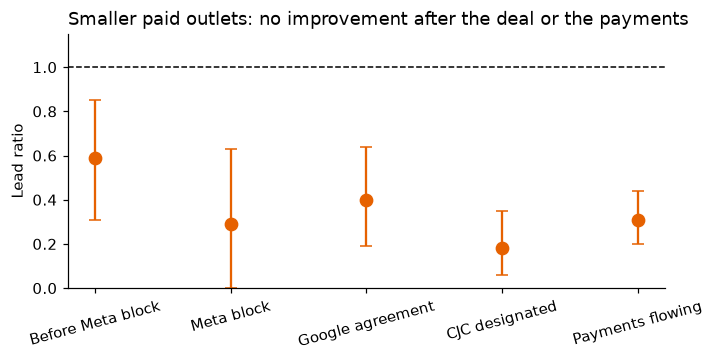

In [5]:
periods = [('2022-01-01', 'Before Meta block'), ('2023-08-01', 'Meta block'), ('2023-11-29', 'Google agreement'),
           ('2024-06-07', 'CJC designated'), ('2025-03-11', 'Payments flowing')]
day = pd.to_datetime(cl.timestamp.str[:8])
cl['period'] = pd.cut(day, bins=[pd.Timestamp(p) for p, _ in periods] + [pd.Timestamp('2030-01-01')],
                      labels=[n for _, n in periods], right=False)
rows = []
for name in [n for _, n in periods]:
    d = cl[cl.period == name]
    r, lo, hi, leads, exp = lead_ratio(d, d.small)
    rows.append({'period': name, 'leads': leads, 'expected': round(exp, 1), 'lead_ratio': round(r, 2),
                 'ci_low': round(lo, 2), 'ci_high': round(hi, 2)})
per = pd.DataFrame(rows)
print(per.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
x = range(len(per))
ax.errorbar(x, per.lead_ratio, yerr=[per.lead_ratio - per.ci_low, per.ci_high - per.lead_ratio],
            fmt='o', color=ORANGE, capsize=4, ms=8)
ax.axhline(1, ls='--', color='black', lw=1)
ax.set_xticks(list(x), per.period, rotation=15); ax.set_ylim(0, 1.15); ax.set_ylabel('Lead ratio')
ax.set_title('Smaller paid outlets: no improvement after the deal or the payments', loc='left')
save(fig, '4_lead_ratio_over_time')

## 5. Search: the same measure in Google News search and Google Search

31 recent stories covered by both a smaller paid outlet and a major one. Each search's on-story results are treated like one story card; "contested" = at least one smaller and one major outlet among them.

                          contested queries  small on top  expected  \
engine                                                                
Google News search                     27.0           3.0       8.1   
Google Search (News tab)               28.0           5.0       8.6   

                          lead_ratio  
engine                                
Google News search              0.37  
Google Search (News tab)        0.58  


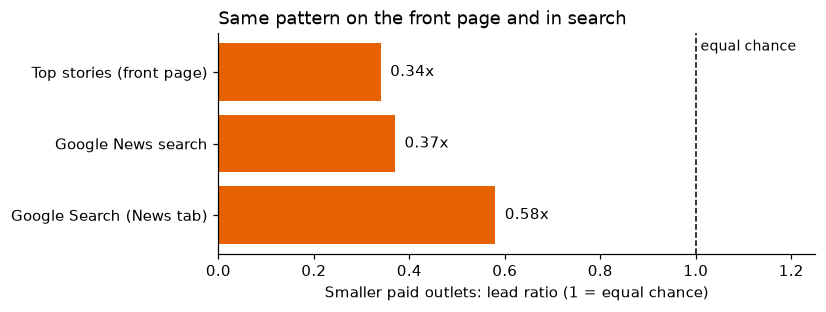

In [6]:
res = pd.read_csv(f'{DATA}/search_check/search_results.csv')
res = res[res.on_story.astype(str).eq('True')].sort_values('rank')
q = res.groupby(['story_id', 'engine']).agg(n=('size_group', 'size'),
                                            n_small=('size_group', lambda k: (k == 'small').sum()),
                                            n_major=('size_group', lambda k: (k == 'major').sum()),
                                            top=('size_group', 'first')).reset_index()
q = q[(q.n_small > 0) & (q.n_major > 0)]
srch = q.groupby('engine').apply(lambda g: pd.Series({'contested queries': len(g), 'small on top': int((g.top == 'small').sum()),
                                                      'expected': round((g.n_small / g.n).sum(), 1),
                                                      'lead_ratio': round((g.top == 'small').sum() / (g.n_small / g.n).sum(), 2)}),
                                 include_groups=False)
srch.index = srch.index.map({'gnews': 'Google News search', 'gsearch': 'Google Search (News tab)'})
print(srch)

comp = pd.concat([pd.Series({'Top stories (front page)': lr.query("edition == 'both' and group == 'Smaller paid outlets'").lead_ratio.iloc[0]}),
                  srch.lead_ratio])
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(comp.index[::-1], comp.values[::-1], color=ORANGE)
ax.axvline(1, ls='--', color='black', lw=1)
for i, v in enumerate(comp.values[::-1]):
    ax.text(v + 0.02, i, f'{v:.2f}x', va='center')
ax.text(1.01, 2.3, 'equal chance', fontsize=9)
ax.set_xlim(0, 1.25); ax.set_xlabel('Smaller paid outlets: lead ratio (1 = equal chance)')
ax.set_title('Same pattern on the front page and in search', loc='left')
save(fig, '5_search_vs_front_page')

## 6. Civic outcomes: acclaimed mayors in small towns

Towns under 10,000 people. Head of council acclaimed in 2026 (no contest), by whether the town has its own news outlet. A correlation, not a causal effect.

                acclaimed  towns     share
has_own_outlet                            
No own outlet          77    224  0.343750
Own outlet              6     39  0.153846


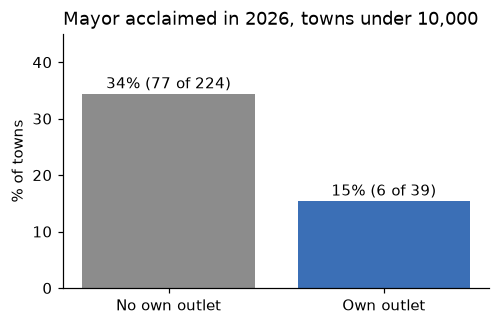

In [7]:
civ = pd.read_csv(f'{DATA}/ontario_towns/civic_outcomes.csv')
small_towns = civ[civ.population_2021 < 10000]
c = small_towns.groupby('has_own_outlet').head_acclaimed_2026.agg(acclaimed='sum', towns='count')
c['share'] = c.acclaimed / c.towns
c.index = c.index.map({True: 'Own outlet', False: 'No own outlet'})
print(c)

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(c.index, c.share * 100, color=[GREY, BLUE])
for b, (_, r) in zip(bars, c.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{r.share:.0%} ({int(r.acclaimed)} of {int(r.towns)})", ha='center')
ax.set_ylim(0, 45); ax.set_ylabel('% of towns')
ax.set_title('Mayor acclaimed in 2026, towns under 10,000', loc='left')
save(fig, '6_acclaimed_mayors')